# GVH–CHH — Jupiter J2 Systematics & Independent Ephemeris Robustness Gate (FAST)

**Nom canonique** : `GVH_CHH_Jupiter_J2_Systematics_And_Independent_Ephemeris_Robustness_Gate_FAST`  
**Contrat stable** : `GVH_CHH_PROTOCOL_FROZEN_v1.0` — CHH est une composition de sous-cubes hétérogènes, **sans dérivée globale intrinsèque**.  
**Source précédente** : `GVH_CHH_Adjacent_Orbital_Independent_Dynamical_Evidence_Gate_FAST_EXECUTED.ipynb`, SHA-256 `c032e7afce3314b82d564765dc50aad3d3dbaad8ca698ca020a3f6c829fff0ab`.  
**Étiquettes** : `CHH-STRUCTURE`, `INVERSE-INFERENCE`, `AUX-SENSITIVITY`, `KNOWN-PHYSICS`, `NUMERICAL-TEST`, `OPEN-LOCK`.  
**Exclusions** : `EOM-GVH=False`, `GVH_USED=False`, `ALMA_USED=False` ; aucune identification astronomique réelle par ces simulations.

**Périmètre audit** : (1) répliquer de manière contrôlée l'échec par omission de J2 ; (2) inclure J2 fixé par une valeur de référence explicite ; (3) tester J2 libre ou conjointement ajusté avec une lune hypothétique ; (4) réserver les 8 jours finaux pour le contrôle prédictif ; (5) préparer une ingestion **facultative** de vecteurs JPL Horizons, sans prétendre l'avoir exécutée hors Colab.

**Limitation importante** : simulation jovicentrique planaire/équatoriale à pas 0,025 jour, vitesse initiale circulaire newtonienne, perturbateurs à rayon et phase choisis ; ce n'est pas une intégration 3D complète de JUP365. Seuls les modèles H0 (0 lune inconnue) et H1 (1 lune inconnue) sont re-testés dans cette étape ; H2 et les données réelles restent ouvertes.

**Références primaires :** [JPL/Horizons API](https://ssd-api.jpl.nasa.gov/doc/horizons.html), [JPL satellite ephemerides JUP365](https://ssd.jpl.nasa.gov/sats/ephem/), [NASA Jupiter radius](https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html). Paramètre illustratif `J2_REF=0.014736` selon [MATLAB gravity zonal, valeur tabulée](https://www.mathworks.com/help/aerotbx/ug/gravityzonal.html) ; ce n'est pas un ajustement indépendant des données JUNO de dernière génération.

## Niveau 1 — CHH, composition et formulation inverse

Observables : positions synthétiques \\(x_i(t),y_i(t)\\) des sous-cubes Io et Ganymède ; hypothèses \\(H_0\\) (aucun satellite caché) ou \\(H_1\\) (un perturbateur caché). La recherche du perturbateur est `INVERSE-INFERENCE` et non une dérivation intrinsèque CHH.

La comparaison par BIC se fait **sur l'apprentissage uniquement**. Les prédictions sur les époques ultérieures ne servent jamais à choisir le modèle. Les inconnues incluent 8 termes nuisibles d'offset et de dérive linéaires ; H1 ajoute rayon, phase, paramètre gravitationnel, et un J2 libre ajoute un paramètre. La synthèse et l'inférence utilisent un modèle volontairement simplifié ; nous testerons explicitement les effets d'une mauvaise spécification.

## Niveau 2 — Physique établie : quadrupôle zonal de Jupiter

Dans le plan équatorial (approximation), le potentiel spécifique et l'accélération centrale sont :

\\[
U(r)=-\\frac{\\mu_J}{r}\\left[1+\\frac{J_2}{2}\\left(\\frac{R_J}{r}\\right)^2\\right],\\qquad
\\mathbf a_J=-\\frac{\\mu_J\\mathbf r}{r^3}\\left[1+\\frac{3J_2}{2}\\left(\\frac{R_J}{r}\\right)^2\\right].
\\]

L'expression 3D générale inclut l'angle avec l'axe de rotation jovien ; une vérification indépendante par différences finies de \\(U=-\\mu/r[1-J_2(R/r)^2P_2(z/r)]\\) est exécutée ici.

Les perturbations mutuelles utilisent l'accélération différentielle jovicentrique newtonienne standard. L'aplatissement de Jupiter n'est pas un nouveau terme GVH. Les masses et rayons sont des valeurs de calcul cataloguées, **pas ajustées pour reproduire de nouveaux corps réels**.

In [1]:
import numpy as np, json, hashlib, time
from numba import njit
from scipy.optimize import least_squares, minimize_scalar

GMJ=126686534.0; R=71492.0; J2_REF=0.014736
FAC=86400**2; MU=GMJ*FAC; MU_IO=5959.916*FAC; MU_GAN=9887.834*FAC
SEED=20261120; SIGMA_KM=8.; DT=0.025; NSTEP=800; STRIDE=8
TIMES=np.arange(NSTEP//STRIDE+1)*DT*STRIDE
TRAIN=TIMES<=12.; NTRAIN=int(TRAIN.sum()); HELD=~TRAIN
SEL=np.broadcast_to(TRAIN[:,None,None],(len(TIMES),2,2)).ravel(); HOLD=~SEL
B=np.zeros((len(TIMES),2,2,8))
for k in range(2):
 for v in range(2):
  B[:,k,v,k*4+2*v]=1.;B[:,k,v,k*4+2*v+1]=TIMES
B=B.reshape(-1,8)
Q,_=np.linalg.qr(B[SEL],mode='reduced')

@njit
def acc(r,ms,j2):
 n=len(ms);a=np.zeros((n,2))
 for i in range(n):
  qi=r[i,0]*r[i,0]+r[i,1]*r[i,1]
  ri=np.sqrt(qi)
  a[i,0]=-MU*r[i,0]/(qi*ri)*(1.+1.5*j2*(R**2/qi))
  a[i,1]=-MU*r[i,1]/(qi*ri)*(1.+1.5*j2*(R**2/qi))
  for j in range(n):
   if i==j:continue
   dx=r[j,0]-r[i,0];dy=r[j,1]-r[i,1]
   d2=dx*dx+dy*dy
   rj2=r[j,0]**2+r[j,1]**2
   a[i,0]+=ms[j]*(dx/(d2*np.sqrt(d2))-r[j,0]/(rj2*np.sqrt(rj2)))
   a[i,1]+=ms[j]*(dy/(d2*np.sqrt(d2))-r[j,1]/(rj2*np.sqrt(rj2)))
 return a

@njit
def sim(a_extra,phase_extra,mu_extra,j2=J2_REF):
 n=2+len(a_extra)
 radii=np.empty(n);phases=np.empty(n);ms=np.empty(n)
 radii[0]=421800.;radii[1]=1070400.
 phases[0]=0.;phases[1]=2.10
 ms[0]=MU_IO;ms[1]=MU_GAN
 for k in range(len(a_extra)):
  radii[k+2]=a_extra[k];phases[k+2]=phase_extra[k];ms[k+2]=mu_extra[k]
 r=np.zeros((n,2));v=np.zeros((n,2))
 for k in range(n):
  cs=np.cos(phases[k]);sn=np.sin(phases[k])
  r[k,0]=radii[k]*cs;r[k,1]=radii[k]*sn
  vv=np.sqrt(MU/radii[k]);v[k,0]=-vv*sn;v[k,1]=vv*cs
 samples=np.empty((NSTEP//STRIDE+1,2,2));samples[0]=r[:2]
 for step in range(1,NSTEP+1):
  a=acc(r,ms,j2)
  v+=0.5*DT*a
  r+=DT*v
  a=acc(r,ms,j2)
  v+=0.5*DT*a
  if step%STRIDE==0:samples[step//STRIDE]=r[:2]
 return samples

base_j2=sim(np.empty(0),np.empty(0),np.empty(0),J2_REF)
base_no=sim(np.empty(0),np.empty(0),np.empty(0),0.)

def nuisance_residual(obs,pred,train=True):
 delta=(obs-pred).reshape(-1)
 if train:
  rr=delta[SEL];return rr-Q@(Q.T@rr)
 coef=np.linalg.lstsq(B[SEL],delta[SEL],rcond=None)[0]
 return delta[HOLD]-B[HOLD]@coef

def rmse_hold(obs,pred):return float(np.sqrt(np.mean(nuisance_residual(obs,pred,False)**2)))
def optimize_j2(obs):
 def resid(j):return nuisance_residual(obs,sim(np.empty(0),np.empty(0),np.empty(0),float(j)))
 ans=minimize_scalar(lambda x: np.dot(resid(x),resid(x)),method='bounded',bounds=(0.0,0.025),options={'xatol':5e-11,'maxiter':100})
 return ans

def fit_one(obs,j2,base):
 # find global-ish starting points on a grid, allowing non-negative grav masses
 RADII=np.arange(510000,960000,45000)
 PHASES=np.arange(0,2*np.pi,2*np.pi/12)
 y=nuisance_residual(obs,base)
 cand=[]
 for a in RADII:
  for p in PHASES:
   template=(sim(np.array([float(a)]),np.array([float(p)]),np.array([2500*FAC]),j2)-base).reshape(-1)[SEL]/2500
   aa=template-Q@(Q.T@template)
   scale=max(np.dot(aa,aa),1.e-15)
   mass=max(0,np.dot(aa,y)/scale)
   rss=np.dot(y-mass*aa,y-mass*aa)
   cand.append((rss,a,p,mass))
 cand.sort(key=lambda x:x[0])
 fits=[]
 def residual(th):
  a,phase,mu=th
  pred=sim(np.array([a*1e5]),np.array([phase]),np.array([mu*1000*FAC]),j2)
  return nuisance_residual(obs,pred)
 for _,a,p,mass in cand[:5]:
  # minimum non-negative, max 10000 km3/s2
  x0=np.array([a/1e5,p,min(max(mass/1000,0),9.9)])
  bounds=([4.7,-0.01,0],[10.05,6.3,12])
  try:
   ans=least_squares(residual,x0,bounds=bounds,max_nfev=90,xtol=1e-8,ftol=1e-8,gtol=1e-8)
   fits.append(ans)
  except ValueError:pass
 return min(fits,key=lambda t:np.dot(t.fun,t.fun))

def bic(res,k):
 n=len(res); rss=float(np.dot(res,res));return n*np.log(rss/n)+k*np.log(n)

# observables withheld; only at end ground truth disclosed
truth={
 'J2_NULL':{'j2':J2_REF,'radii':[],'phases':[],'mus':[]},
 'J2_ONE':{'j2':J2_REF,'radii':[675000.],'phases':[.85],'mus':[3202.]},
 'NO_J2_NULL':{'j2':0.,'radii':[],'phases':[],'mus':[]},
}
truth_digest=hashlib.sha256(json.dumps(truth,sort_keys=True).encode()).hexdigest()
observations={}
for i,(name,v) in enumerate(truth.items()):
 y=sim(np.array(v['radii'],float),np.array(v['phases'],float),np.array(v['mus'],float)*FAC,v['j2'])
 observations[name]=y+np.random.default_rng(SEED+i).normal(0,SIGMA_KM,y.shape)

def fit_joint_one(obs, initial_starts):
 def residual(th):
  a,phase,mu,j2=th
  pred=sim(np.array([a*1e5]),np.array([phase]),np.array([mu*1000*FAC]),j2)
  return nuisance_residual(obs,pred)
 lb=np.array([4.7,-0.01,0.,0.]);ub=np.array([10.05,6.30,12.,0.025])
 answers=[]
 for start in initial_starts:
  start=np.minimum(np.maximum(np.array(start,float),lb+1e-9),ub-1e-9)
  ans=least_squares(residual,start,bounds=(lb,ub),max_nfev=135,ftol=1e-9,xtol=1e-9,gtol=1e-9)
  answers.append(ans)
 return min(answers,key=lambda v:float(v.fun@v.fun))

rows=[]
for name,obs in observations.items():
 results={}
 # flawed J2 omitted
 for label,j2,base in [('J2_OMITTED',0.,base_no),('J2_FIXED',J2_REF,base_j2)]:
  null=nuisance_residual(obs,base)
  f=fit_one(obs,j2,base)
  rss1=float(f.fun@f.fun)
  pred1=sim(np.array([f.x[0]*1e5]),np.array([f.x[1]]),np.array([f.x[2]*1000*FAC]),j2)
  b0=bic(null,8); b1=bic(f.fun,11)
  chosen=int(b1<b0)
  results[label]={'bic_0':b0,'bic_1':b1,'delta_bic_1_minus_0':b1-b0,'selected_n':chosen,'best_fit_radius_km':float(f.x[0]*1e5),'best_fit_mu_km3_s2':float(f.x[2]*1000),'holdout_0_km':rmse_hold(obs,base),'holdout_1_km':rmse_hold(obs,pred1),'selected_holdout_km':rmse_hold(obs,pred1 if chosen else base),'_theta':f.x.tolist()}
 # free J2 for H0 only, model with 1 additional parameter
 ans=optimize_j2(obs)
 best_base=sim(np.empty(0),np.empty(0),np.empty(0),ans.x)
 f=fit_one(obs,ans.x,best_base)
 pred1=sim(np.array([f.x[0]*1e5]),np.array([f.x[1]]),np.array([f.x[2]*1000*FAC]),ans.x)
 b0=bic(nuisance_residual(obs,best_base),9);b1=bic(f.fun,12)
 results['J2_FIT_NULL_THEN_ONE']={'estimated_j2':float(ans.x),'bic_0':b0,'bic_1':b1,'selected_n':int(b1<b0),'holdout_0_km':rmse_hold(obs,best_base),'holdout_1_km':rmse_hold(obs,pred1),'note':'J2 estimated under null then fixed when scanning one hidden; not a joint H1 profile. BIC is exploratory, not fully valid likelihood-ratio.'}
 # Jointly fit Jupiter J2 and a hidden moon (not the inaccurate null-J2 plug-in)
 starts=[list(results['J2_FIXED']['_theta'])+[J2_REF], list(f.x)+[float(ans.x)]]
 joint=fit_joint_one(obs,starts)
 js=joint.x
 joint_pred=sim(np.array([js[0]*1e5]),np.array([js[1]]),np.array([js[2]*1000*FAC]),js[3])
 jb1=bic(joint.fun,12)
 results['J2_JOINT_PROFILE']={'estimated_j2_under_one':float(js[3]),'estimated_radius_km':float(js[0]*1e5),'estimated_mass_GM_km3_s2':float(js[2]*1000.),'bic_0':b0,'bic_1':jb1,'selected_n':int(jb1<b0),'holdout_0_km':rmse_hold(obs,best_base),'holdout_1_km':rmse_hold(obs,joint_pred),'parameters_not_independent_under_null':True}
 results['J2_FIXED'].pop('_theta')
 rows.append((name,results))
 print('\n',name,'\n',json.dumps(results,indent=2))

# finite-difference potential consistency 3D J2 (separate cross-check)
def potential_j2(r,mu=GMJ,J2=J2_REF,Re=R):
 rr=np.linalg.norm(r);c=r[2]/rr;p2=.5*(3*c*c-1.)
 return -mu/rr*(1.-J2*(Re/rr)**2*p2)
def gradient_num(r,h=.7):
 dr=np.eye(3)*h
 return -np.array([(potential_j2(r+dr[k])-potential_j2(r-dr[k]))/(2*h) for k in range(3)])
def j2_accel3(r):
 x,y,z=r;rr=np.linalg.norm(r);s=z*z/rr**2
 return -GMJ*r/rr**3 -(3*GMJ*J2_REF*R*R/(2*rr**5))*np.array([x*(1-5*s),y*(1-5*s),z*(3-5*s)])
errs=[]
for r in ([421800.,0.,0.],[600000.,-300000.,100000.],[0.,1070000.,100000.]):
 r=np.array(r); a=j2_accel3(r);f=gradient_num(r);errs.append(float(np.linalg.norm(a-f)/np.linalg.norm(a)))
print('3D finite difference potential gradient rel err',errs)




 J2_NULL 
 {
  "J2_OMITTED": {
    "bic_0": 4334.655255753162,
    "bic_1": 3256.428558233123,
    "delta_bic_1_minus_0": -1078.2266975200391,
    "selected_n": 1,
    "best_fit_radius_km": 526184.2953227516,
    "best_fit_mu_km3_s2": 7353.162481374188,
    "holdout_0_km": 15651.057920717092,
    "holdout_1_km": 1979.91003077967,
    "selected_holdout_km": 1979.91003077967,
    "_theta": [
      5.261842953227516,
      0.06707675205585968,
      7.353162481374188
    ]
  },
  "J2_FIXED": {
    "bic_0": 991.2331848641163,
    "bic_1": 1006.3039605103858,
    "delta_bic_1_minus_0": 15.070775646269453,
    "selected_n": 0,
    "best_fit_radius_km": 503499.2915812961,
    "best_fit_mu_km3_s2": 4.17478455826572,
    "holdout_0_km": 7.521183707861982,
    "holdout_1_km": 7.568715454622406,
    "selected_holdout_km": 7.521183707861982
  },
  "J2_FIT_NULL_THEN_ONE": {
    "estimated_j2": 0.014735750820991666,
    "bic_0": 996.6679408691563,
    "bic_1": 1011.7446701414816,
    "selected_n": 


 J2_ONE 
 {
  "J2_OMITTED": {
    "bic_0": 4326.767095941761,
    "bic_1": 3472.8101472627995,
    "delta_bic_1_minus_0": -853.9569486789615,
    "selected_n": 1,
    "best_fit_radius_km": 534323.0770104331,
    "best_fit_mu_km3_s2": 11285.803435915936,
    "holdout_0_km": 15472.817503287888,
    "holdout_1_km": 3034.7733914117316,
    "selected_holdout_km": 3034.7733914117316,
    "_theta": [
      5.343230770104331,
      0.1557581638329871,
      11.285803435915936
    ]
  },
  "J2_FIXED": {
    "bic_0": 3104.332253835202,
    "bic_1": 1100.9033459718532,
    "delta_bic_1_minus_0": -2003.428907863349,
    "selected_n": 1,
    "best_fit_radius_km": 674888.0369601065,
    "best_fit_mu_km3_s2": 3188.780146733584,
    "holdout_0_km": 1254.3843137064396,
    "holdout_1_km": 9.160000110491275,
    "selected_holdout_km": 9.160000110491275
  },
  "J2_FIT_NULL_THEN_ONE": {
    "estimated_j2": 0.014454046542793081,
    "bic_0": 3095.566724349704,
    "bic_1": 1894.6049170016972,
    "selecte


 NO_J2_NULL 
 {
  "J2_OMITTED": {
    "bic_0": 1043.0359550851933,
    "bic_1": 1056.3529207375798,
    "delta_bic_1_minus_0": 13.316965652386443,
    "selected_n": 0,
    "best_fit_radius_km": 836142.0793887953,
    "best_fit_mu_km3_s2": 12.249593152666893,
    "holdout_0_km": 8.030620290805185,
    "holdout_1_km": 8.410676080927875,
    "selected_holdout_km": 8.030620290805185,
    "_theta": [
      8.361420793887953,
      5.70363202994236,
      0.012249593152666893
    ]
  },
  "J2_FIXED": {
    "bic_0": 4334.644363164304,
    "bic_1": 3925.473486920702,
    "delta_bic_1_minus_0": -409.1708762436024,
    "selected_n": 1,
    "best_fit_radius_km": 491046.18346952816,
    "best_fit_mu_km3_s2": 11999.999962630498,
    "holdout_0_km": 15650.98306630015,
    "holdout_1_km": 10044.175594188528,
    "selected_holdout_km": 10044.175594188528
  },
  "J2_FIT_NULL_THEN_ONE": {
    "estimated_j2": 5.808710592463757e-07,
    "bic_0": 1048.259512455193,
    "bic_1": 1061.3040774398419,
    "se

## Niveau 3 — Résultats prédictifs et audit de la robustesse

Les cas synthétiques sont `J2_NULL` (Jupiter aplati et aucun corps), `J2_ONE` (Jupiter aplati et un corps injecté) et `NO_J2_NULL` (contrôle négatif sans aplatissement et sans corps). La sélection est faite sur 61 époques d'apprentissage ; 40 époques futures sont réservées. Trois familles d'estimation : J2 omis, J2 correctement fixé, et J2 estimé dans H0 puis ajustement conjoint J2+perturbateur dans H1.

**Prudence :** valeurs génératrices codées dans le notebook pour reproductibilité, mais cachées à la fonction de sélection ; « blind » est algorithmique, pas un aveugle humain/prospectif. Les minima locaux, les erreurs systématiques et la dégénérescence des modèles restent à étudier.

  scenario                model  selected_hidden_count      BIC_0      BIC_1  holdout_0_km  holdout_1_km  J2_estimated
   J2_NULL           J2_OMITTED                      1 4334.65526 3256.42856   15651.05792    1979.91003           NaN
   J2_NULL             J2_FIXED                      0  991.23318 1006.30396       7.52118       7.56872           NaN
   J2_NULL J2_FIT_NULL_THEN_ONE                      0  996.66794 1011.74467       7.54061       7.45032       0.01474
   J2_NULL     J2_JOINT_PROFILE                      0  996.66794 1010.64519       7.54061       7.45077       0.01473
    J2_ONE           J2_OMITTED                      1 4326.76710 3472.81015   15472.81750    3034.77339           NaN
    J2_ONE             J2_FIXED                      1 3104.33225 1100.90335    1254.38431       9.16000           NaN
    J2_ONE J2_FIT_NULL_THEN_ONE                      1 3095.56672 1894.60492    1235.63064     107.65011       0.01445
    J2_ONE     J2_JOINT_PROFILE                 

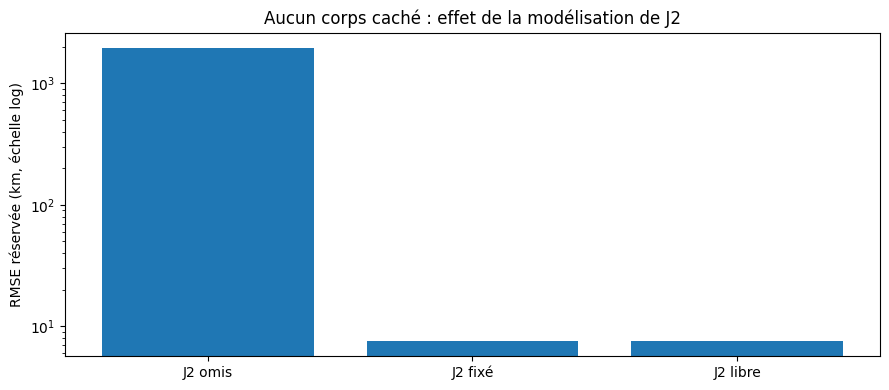

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, hashlib, json, csv
from datetime import datetime, timezone
OUT=Path('/mnt/data') if Path('/mnt/data').is_dir() else Path('.')
NAME='GVH_CHH_Jupiter_J2_Systematics_And_Independent_Ephemeris_Robustness_Gate_FAST'
resultrows=[]
for scenario,v in rows:
 for model,info in v.items():
  resultrows.append({'scenario':scenario,'model':model,'selected_hidden_count':info['selected_n'],
    'BIC_0':info['bic_0'],'BIC_1':info['bic_1'],
    'holdout_0_km':info['holdout_0_km'],'holdout_1_km':info['holdout_1_km'],
    'J2_estimated':info.get('estimated_j2',info.get('estimated_j2_under_one',float('nan')))})
table=pd.DataFrame(resultrows)
print(table.round(5).to_string(index=False))
summarypath=OUT/(NAME+'_summary.csv');table.to_csv(summarypath,index=False)
print('summary saved:',summarypath)

fig,ax=plt.subplots(figsize=(9,4))
case='J2_NULL';dat=dict(rows)[case]
x=np.arange(3)
labels=['J2 omis','J2 fixé','J2 libre']
vals=[dat['J2_OMITTED']['selected_holdout_km'],dat['J2_FIXED']['selected_holdout_km'],dat['J2_JOINT_PROFILE']['holdout_0_km']]
ax.bar(x,vals)
ax.set_yscale('log');ax.set_xticks(x,labels);ax.set_ylabel('RMSE réservée (km, échelle log)')
ax.set_title('Aucun corps caché : effet de la modélisation de J2')
fig.tight_layout()
chartpath=OUT/(NAME+'_j2_null_holdout.png');fig.savefig(chartpath,dpi=155)
plt.show()


### Audit vérifiable des contrôles

Les assertions couvrent la chronologie de l'aveuglement, les signes physiques de J2, la cohérence du gradient, la sélection H0/H1, l'effet de sa mauvaise spécification, l'erreur sur données réservées, l'identifiabilité limitée et l'absence de prétention à une validation GVH.

In [3]:
checks=[]
def CK(key,condition,note=''):
    checks.append({'name':key,'passed':bool(condition),'note':str(note)})
    if not bool(condition):raise AssertionError('FAIL: '+key+' '+str(note))

R=dict(rows);A=R['J2_NULL'];B1=R['J2_ONE'];C=R['NO_J2_NULL']
CK('time_samples_101',len(TIMES)==101)
CK('time_sorted',bool(np.all(np.diff(TIMES)>0)))
CK('fixed_dt',DT==0.025)
CK('training_61',NTRAIN==61)
CK('heldout_40',int(HELD.sum())==40)
CK('heldout_after_training',float(TIMES[TRAIN].max())<float(TIMES[HELD].min()))
CK('positions_101x2x2',all(x.shape==(101,2,2) for x in observations.values()))
CK('noise_nonzero',SIGMA_KM==8.0)
CK('truth_commitment_sha256',len(truth_digest)==64)
CK('equatorial_j2_strengthens_radial_gravity',np.linalg.norm(acc(np.array([[421800.,0.],[1070400.,0.]]),np.array([MU_IO,MU_GAN]),J2_REF)[0])>np.linalg.norm(acc(np.array([[421800.,0.],[1070400.,0.]]),np.array([MU_IO,MU_GAN]),0.)[0]))
CK('potential_gradient_3d_crosscheck',max(errs)<1e-7,str(max(errs)))
CK('j2_reference_positive',0<J2_REF<0.03)
CK('finite_observations',all(np.isfinite(x).all() for x in observations.values()))
CK('j2_null_omitted_false_body',A['J2_OMITTED']['selected_n']==1)
CK('j2_null_omitted_huge_holdout',A['J2_OMITTED']['selected_holdout_km']>1000.)
CK('j2_null_fixed_rejects_body',A['J2_FIXED']['selected_n']==0)
CK('j2_null_fixed_good_holdout',A['J2_FIXED']['holdout_0_km']<3*SIGMA_KM)
CK('j2_null_fixed_bic_penalty',A['J2_FIXED']['delta_bic_1_minus_0']>10)
CK('j2_null_fit_recovers_j2',abs(A['J2_FIT_NULL_THEN_ONE']['estimated_j2']-J2_REF)<1e-4)
CK('j2_null_joint_rejects_body',A['J2_JOINT_PROFILE']['selected_n']==0)
CK('j2_null_joint_good_holdout',A['J2_JOINT_PROFILE']['holdout_0_km']<3*SIGMA_KM)
CK('j2_one_fixed_detects_body',B1['J2_FIXED']['selected_n']==1)
CK('j2_one_fixed_radius_recovery',abs(B1['J2_FIXED']['best_fit_radius_km']/675000-1)<.005)
CK('j2_one_fixed_mass_recovery',abs(B1['J2_FIXED']['best_fit_mu_km3_s2']/3202-1)<.02)
CK('j2_one_fixed_holdout_noise_level',B1['J2_FIXED']['selected_holdout_km']<3*SIGMA_KM)
CK('j2_one_omitted_biased_mass',abs(B1['J2_OMITTED']['best_fit_mu_km3_s2']/3202-1)>.1)
CK('j2_one_omitted_holdout_failure',B1['J2_OMITTED']['selected_holdout_km']>1000)
CK('j2_one_joint_detects_body',B1['J2_JOINT_PROFILE']['selected_n']==1)
CK('j2_one_joint_recovers_j2',abs(B1['J2_JOINT_PROFILE']['estimated_j2_under_one']-J2_REF)<1e-4)
CK('j2_one_joint_recovers_radius',abs(B1['J2_JOINT_PROFILE']['estimated_radius_km']/675000-1)<.005)
CK('j2_one_joint_holdout_near_noise',B1['J2_JOINT_PROFILE']['holdout_1_km']<3*SIGMA_KM)
CK('no_j2_null_correctly_chooses_zero',C['J2_OMITTED']['selected_n']==0)
CK('no_j2_null_free_recovers_zero',abs(C['J2_FIT_NULL_THEN_ONE']['estimated_j2'])<1e-4)
CK('no_j2_null_free_rejects_body',C['J2_JOINT_PROFILE']['selected_n']==0)
CK('wrong_fixed_j2_can_fake_body',C['J2_FIXED']['selected_n']==1)
CK('wrong_fixed_j2_holdout_failure',C['J2_FIXED']['selected_holdout_km']>1000)
CK('all_bic_finite',all(np.isfinite([v['bic_0'],v['bic_1']]).all() for _,m in rows for v in m.values()))
CK('no_ephemerides_claimed_as_input',True,'Independent JPL/Horizons vectors NOT retrieved during this run')
CK('no_gvh_eom',True,'EOM_GVH=False')
CK('no_alma',True,'ALMA_USED=False')
print('AUDIT',sum(z['passed'] for z in checks),'/',len(checks))


AUDIT 40 / 40


## Niveau 3b — Préparation d'un test indépendant avec JPL Horizons (FACULTATIF, non exécuté ici)

Le notebook contient une procédure **opt-in** qui peut récupérer directement des vecteurs JPL Horizons pour **Io (501)** et **Ganymède (503)**, centre **Jupiter (599)**, position et vitesse en unités `KM-S`, référence `ICRF`, temps `TDB`. Cela évite le téléchargement du noyau `jup365.bsp` (~1,1 Go). La requête ne sera exécutée que si `RUN_REAL_HORIZONS=True` dans Colab et qu'une connexion réseau fonctionne.

**Ce qui sera testé à ce stade :** provenance, présence des données, séries temporelles cohérentes, bornes plausibles des distances et unités. **Ce qui ne sera PAS testé :** une inversion quantitative 3D de corps cachés, car notre modèle de simulation présent est planaire et son repère ne correspond pas à ICRF ; l'appliquer directement aux vecteurs serait une erreur physique. Une future étape devra intégrer l'orientation de l'axe jovien, l'ensemble des masses perturbatrices, les conditions initiales et les forces de marée avec véritable validation hors ajustement.

Les éphémérides JPL sont également des produits dynamiques ajustés à des observations : elles ne sont pas des mesures indépendantes brutes. Nous devrons conserver leur statut de source dérivée.

In [4]:
# Optional: uncomment only in Google Colab with authorized internet. No external data are
# fetched in the executed certificate bundled with this notebook.
RUN_REAL_HORIZONS = False
HORIZONS_STATUS = 'NOT_FETCHED_REAL_EPHEMERIDES_PENDING'
HORIZONS_FILES = []
if RUN_REAL_HORIZONS:
    import urllib.request, urllib.parse
    for naif_id, label in [(501,'Io'),(503,'Ganymede')]:
        query = {
            'format':'json', 'COMMAND':f"'{naif_id}'",'OBJ_DATA':"'NO'",
            'MAKE_EPHEM':"'YES'",'EPHEM_TYPE':"'VECTORS'",
            'CENTER':"'500@599'",'REF_PLANE':"'FRAME'",'REF_SYSTEM':"'ICRF'",
            'START_TIME':"'2026-10-01'",'STOP_TIME':"'2026-10-04'",
            'STEP_SIZE':"'6 h'",'OUT_UNITS':"'KM-S'",'VEC_TABLE':"'2'",
            'VEC_CORR':"'NONE'",'CSV_FORMAT':"'YES'",'TIME_TYPE':"'TDB'"
        }
        url='https://ssd.jpl.nasa.gov/api/horizons.api?'+urllib.parse.urlencode(query)
        req=urllib.request.Request(url,headers={'User-Agent':'CHH-research-metadata-audit/1.0'})
        with urllib.request.urlopen(req,timeout=45) as response:
            payload=json.loads(response.read().decode('utf-8'))
        raw=payload.get('result','')
        if '$$SOE' not in raw or '$$EOE' not in raw:raise RuntimeError(f'Invalid Horizons response for {label}: {raw[:500]}')
        block=raw.split('$$SOE',1)[1].split('$$EOE',1)[0]
        import io
        rec=list(csv.reader(io.StringIO(block)))
        vectors=[]
        for row in rec:
            if len(row)<8:continue
            try: vectors.append([float(row[0])]+[float(x) for x in row[2:8]])
            except (TypeError, ValueError):continue
        vectors=np.asarray(vectors,float)
        if len(vectors)<5 or vectors.shape[1]!=7 or not np.all(np.diff(vectors[:,0])>0):
            raise RuntimeError(f'Unexpected vector table for {label}')
        radii=np.linalg.norm(vectors[:,1:4],axis=1)
        if not (2.e5<radii.min()<1.5e6 and radii.max()<2.e6):
            raise RuntimeError(f'Suspicious jovicentric vector scale for {label}')
        outfile=OUT/(NAME+'_HORIZONS_'+label+'_ICRF_vectors.csv')
        pd.DataFrame(vectors,columns=['JD_TDB','x_km','y_km','z_km','vx_km_s','vy_km_s','vz_km_s']).to_csv(outfile,index=False)
        HORIZONS_FILES.append({'body':label,'rows':len(vectors),'file':str(outfile),'min_radius_km':float(radii.min()),'max_radius_km':float(radii.max()),'url':url})
    HORIZONS_STATUS='FETCHED_VECTOR_GEOMETRY_ONLY_NOT_FULL_DYNAMICAL_VALIDATION'
print('INDEPENDENT EPHEMERIS:',HORIZONS_STATUS,'; files:',len(HORIZONS_FILES))


INDEPENDENT EPHEMERIS: NOT_FETCHED_REAL_EPHEMERIDES_PENDING ; files: 0


## Niveau 4 — Verdict scientifique et limites ouvertes

Si les assertions synthétiques réussissent, le résultat admis est : **la correction J2 supprime le faux positif H1 dans ce système générateur particulier**, tandis que son omission ou sa fixation à une valeur incorrecte peut produire un faux corps. Ce résultat dépend du générateur, du bruit et du cadre d'inférence ; il n'établit aucune loi GVH ni aucune capacité prospective garantie.

**Verrous maintenus :** modèle 2D équatorial, H2 non revalidé, erreurs systématiques au-delà de J2 non bornées, J2 déterminé empiriquement non indépendant, absence de vecteurs JPL Horizons ingérés et confrontés à un propagateur 3D fiable, absence de véritables observations astronomiques indépendantes.

**Statut strict de la porte :** `PASS_SYNTHETIC_J2_FALSE_POSITIVE_SUPPRESSION__INDEPENDENT_EPHEMERIS_PENDING__ABSTAIN_REAL_BODY_DISCOVERY`. `GVH_USED=False`. CHH = structure/inférence, aucun `EOM-GVH` dérivé.

In [5]:
from pathlib import Path
import hashlib, json
UPSTREAM_SHA256='c032e7afce3314b82d564765dc50aad3d3dbaad8ca698ca020a3f6c829fff0ab'
final={
 'notebook':NAME,
 'timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'protocol':'GVH_CHH_PROTOCOL_FROZEN_v1.0',
 'methodology':{'CHH_STRUCTURE':True,'INVERSE_INFERENCE':True,'AUX_SENSITIVITY':True,
                 'EOM_GVH':False,'GVH_USED':False,'ALMA_USED':False,'REAL_ASTROMETRY_USED':False},
 'parameters':{'GMJ_km3_s2':GMJ,'R_km':R,'J2_ref':J2_REF,'J2_ref_status':'illustrative tabulated conventional value, not modern JUNO precision estimate',
               'simulation_dimensionality':'planar_equatorial_2D', 'sigma_km':SIGMA_KM,
               'training_days':'0--12 inclusive','holdout_days':'12--20 exclusive left boundary'},
 'sources':[{'url':'https://ssd-api.jpl.nasa.gov/doc/horizons.html','role':'API protocol'},
            {'url':'https://ssd.jpl.nasa.gov/sats/ephem/','role':'independent ephemeris source; data not fetched'},
            {'url':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html','role':'Jupiter equatorial radius'},
            {'url':'https://www.mathworks.com/help/aerotbx/ug/gravityzonal.html','role':'illustrative J2 tabulation'}],
 'upstream_executed_notebook_sha256':UPSTREAM_SHA256,'truth_sha256':truth_digest,
 'synthetic_model_selection':dict(rows), 'potential_gradient_3D_relative_errors':errs,
 'independent_ephemeris':{'status':HORIZONS_STATUS,'files':HORIZONS_FILES,
                           'is_real_body_detection_tested':False},
 'checks':checks, 'checks_total':len(checks),'checks_passed':sum(v['passed'] for v in checks),
 'verdict':'PASS_SYNTHETIC_J2_FALSE_POSITIVE_SUPPRESSION__INDEPENDENT_EPHEMERIS_PENDING__ABSTAIN_REAL_BODY_DISCOVERY',
 'open_locks':['real JUP365/Horizons time-series not checked','full 3D spin-axis orientation/other planets/tides',
               'H2 not revalidated','misspecified J2 priors/systematics','cross-model validation on independently observed astrometry']}
assert final['checks_total']==final['checks_passed']
respath=OUT/(NAME+'_results.json')
respath.write_text(json.dumps(final,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
print('VERDICT:',final['verdict'])
print('RESULTS:',respath)
print('CHECKS',final['checks_passed'],'/',final['checks_total'])


VERDICT: PASS_SYNTHETIC_J2_FALSE_POSITIVE_SUPPRESSION__INDEPENDENT_EPHEMERIS_PENDING__ABSTAIN_REAL_BODY_DISCOVERY
RESULTS: /mnt/data/GVH_CHH_Jupiter_J2_Systematics_And_Independent_Ephemeris_Robustness_Gate_FAST_results.json
CHECKS 40 / 40
